## Purpose of the Notebook: Emotion Recognition with Wav2Vec2

This notebook trains and evaluates a deep learning model for **Speech Emotion Recognition (SER)**.

### Highlights:
1. **Dataset:** Uses the **SUPERB (ER task)** dataset, built from audio recordings labeled with emotions (Neutral, Happy, Angry, Sad).
2. **Architecture:** Uses Facebook's pre-trained **Wav2Vec2** model, fine-tuned for audio sequence classification.
3. **Techniques:**
   - **Data Augmentation:** Noise injection and volume changes, applied on the fly at every epoch to improve robustness.
   - **Class Imbalance Handling:** Class weights in the loss function.
   - **Optimization:** A learning-rate scheduler (`ReduceLROnPlateau`) and early stopping (`EarlyStopping`).
   - **Thorough Evaluation:** Confusion matrices and detailed metrics (macro-F1, precision, recall) to understand the performance on each emotion.
4. **Reproducibility:** Seeds fixed at every stage, a single GPU, deterministic CUDA algorithms and pinned library versions.


In [1]:
!pip install transformers==5.16.1 datasets==4.8.5 torch==2.11.0 soundfile==0.14.0 evaluate==0.4.6 scikit-learn==1.6.1 seaborn==0.13.2

import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset, concatenate_datasets, Audio
from transformers import (
    Wav2Vec2FeatureExtractor,
    Wav2Vec2ForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    set_seed
)
from sklearn.utils.class_weight import compute_class_weight
import evaluate
from sklearn.metrics import classification_report, confusion_matrix

torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.enable_mem_efficient_sdp(False)

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load the SUPERB dataset (Emotions)
print("\nDownloading SUPERB dataset (ER task)...")
dataset = load_dataset("s3prl/superb", "er")

print("\nOriginal dataset structure:")
print(dataset)

# Class names
raw_class_names = dataset['session1'].features['label'].names
print(raw_class_names)
label_map = {'neu': 'Neutral', 'hap': 'Happy', 'ang': 'Angry', 'sad': 'Sad'}
class_names = [label_map[n] for n in raw_class_names]
print(f"\n  Classes: {class_names}")

SEED = 123
set_seed(SEED)

Using device: cuda



README.md:   0%|          | 0.00/59.2k [00:00<?, ?B/s]

er/session1-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  164MB            

er/session1-00000-of-00001.parquet: downloading bytes:           |  0.00B            

er/session2-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  151MB            

...

Generating session2 split:   0%|          | 0/1023 [00:00<?, ? examples/s]

Generating session3 split:   0%|          | 0/1151 [00:00<?, ? examples/s]

Generating session4 split:   0%|          | 0/1031 [00:00<?, ? examples/s]

Generating session5 split:   0%|          | 0/1241 [00:00<?, ? examples/s]


Original dataset structure:
DatasetDict({
    session1: Dataset({
        features: ['file', 'audio', 'label'],
        num_rows: 1085
    })
    session2: Dataset({
        features: ['file', 'audio', 'label'],
        num_rows: 1023
    })
    session3: Dataset({
        features: ['file', 'audio', 'label'],
        num_rows: 1151
    })
    session4: Dataset({
        features: ['file', 'audio', 'label'],
        num_rows: 1031
    })
    session5: Dataset({
        features: ['file', 'audio', 'label'],
        num_rows: 1241
    })
})
['neu', 'hap', 'ang', 'sad']

  Classes: ['Neutral', 'Happy', 'Angry', 'Sad']


In [3]:
# Sessions 1-4 for training, Session 5 for evaluation
print("\nSplitting dataset into train/eval...")
train_dataset = concatenate_datasets([
    dataset["session1"],
    dataset["session2"],
    dataset["session3"],
    dataset["session4"]
])
eval_dataset = dataset["session5"]

print(f"Train: {len(train_dataset)} samples")
print(f"Eval: {len(eval_dataset)} samples")

# Sampling rate to 16 kHz (required by Wav2Vec2)
print("\nStandardizing sampling rate to 16 kHz...")
train_dataset = train_dataset.cast_column("audio", Audio(sampling_rate=16000))
eval_dataset = eval_dataset.cast_column("audio", Audio(sampling_rate=16000))

print("\n" + "="*60)
print("CLASS IMBALANCE ANALYSIS")
print("="*60)

# Samples per class in training
train_labels = train_dataset['label']
unique, counts = np.unique(train_labels, return_counts=True)

print("\nTRAINING distribution:")
for label, count in zip(unique, counts):
    percentage = (count / len(train_labels)) * 100
    print(f"  {class_names[label]:10s}: {count:4d} samples ({percentage:5.2f}%)")

print("\nAudio duration statistics (Train):")
durations = [len(x['array']) / 16000 for x in train_dataset['audio']]
print(f"  Minimum duration: {min(durations):.2f} seconds")
print(f"  Maximum duration: {max(durations):.2f} seconds")
print(f"  Mean duration: {np.mean(durations):.2f} seconds")
print(f"  Median duration: {np.median(durations):.2f} seconds")


Splitting dataset into train/eval...
Train: 4290 samples
Eval: 1241 samples

Standardizing sampling rate to 16 kHz...

CLASS IMBALANCE ANALYSIS

TRAINING distribution:
  Neutral   : 1324 samples (30.86%)
  Happy     : 1194 samples (27.83%)
  Angry     :  933 samples (21.75%)
  Sad       :  839 samples (19.56%)

Audio duration statistics (Train):
  Minimum duration: 0.58 seconds
  Maximum duration: 29.13 seconds
  Mean duration: 4.57 seconds
  Median duration: 3.63 seconds


In [4]:
max_duration = 10.0
min_duration = 1.0

# Duration filtering
train_dataset = train_dataset.filter(
    lambda x: min_duration <= len(x['audio']['array']) / 16000 <= max_duration
)
eval_dataset = eval_dataset.filter(
    lambda x: min_duration <= len(x['audio']['array']) / 16000 <= max_duration
)

print(f"Train (filtered to {min_duration}-{max_duration}s): {len(train_dataset)} samples")
print(f"Eval (filtered to {min_duration}-{max_duration}s): {len(eval_dataset)} samples")

print("\n" + "="*60)
print("CLASS IMBALANCE ANALYSIS")
print("="*60)

# Samples per class in training
train_labels = train_dataset['label']
unique, counts = np.unique(train_labels, return_counts=True)

print("\nTRAINING distribution:")
for label, count in zip(unique, counts):
    percentage = (count / len(train_labels)) * 100
    print(f"  {class_names[label]:10s}: {count:4d} samples ({percentage:5.2f}%)")

# Compute audio duration statistics
print("\nAudio duration statistics (Train):")
durations = [len(x['array']) / 16000 for x in train_dataset['audio']]
print(f"  Minimum duration: {min(durations):.2f} seconds")
print(f"  Maximum duration: {max(durations):.2f} seconds")
print(f"  Mean duration: {np.mean(durations):.2f} seconds")
print(f"  Median duration: {np.median(durations):.2f} seconds")

Filter:   0%|          | 0/4290 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1241 [00:00<?, ? examples/s]

Train (filtered to 1.0-10.0s): 3995 samples
Eval (filtered to 1.0-10.0s): 1140 samples

CLASS IMBALANCE ANALYSIS

TRAINING distribution:
  Neutral   : 1269 samples (31.76%)
  Happy     : 1122 samples (28.09%)
  Angry     :  878 samples (21.98%)
  Sad       :  726 samples (18.17%)

Audio duration statistics (Train):
  Minimum duration: 1.00 seconds
  Maximum duration: 10.00 seconds
  Mean duration: 4.00 seconds
  Median duration: 3.45 seconds


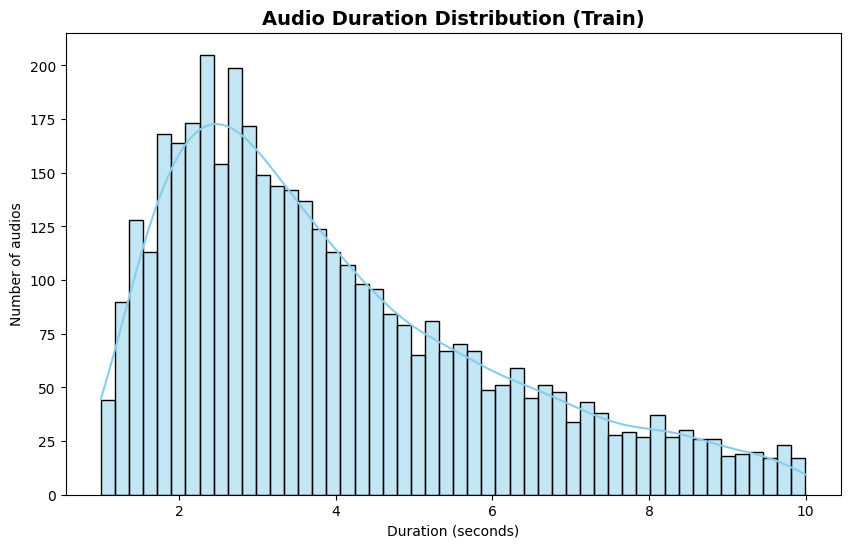

In [5]:
plt.figure(figsize=(10,6))
sns.histplot(durations, bins=50, kde=True, color='skyblue')
plt.title("Audio Duration Distribution (Train)", fontsize=14, fontweight='bold')
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of audios")
plt.show()

In [6]:
# Compute weights to compensate for class imbalance (fewer samples = higher weight)
print("\nComputing weights for imbalanced classes...")

labels_array = np.array(train_dataset['label'])
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(labels_array),
    y=labels_array
)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("\nWeights computed for CrossEntropyLoss:")
for name, weight in zip(class_names, class_weights):
    print(f"  {name:10s}: weight = {weight:.3f}")


Computing weights for imbalanced classes...

Weights computed for CrossEntropyLoss:
  Neutral   : weight = 0.787
  Happy     : weight = 0.890
  Angry     : weight = 1.138
  Sad       : weight = 1.376


In [7]:
# Audio augmentation functions
print("\nConfiguring data augmentation...")

def augment_audio(audio_array, rng, sr=16000):
    """
    Applies random augmentation to the audio to increase data diversity.
    Used only during training, never during evaluation.
    """
    augmented = np.asarray(audio_array, dtype=np.float32).copy()

    # 1. Add Gaussian noise (probability: 50%)
    if rng.random() > 0.5:
        noise_level = rng.uniform(0.001, 0.01)
        noise = rng.standard_normal(len(augmented)).astype(np.float32) * noise_level
        augmented = augmented + noise
        # Clip to avoid out-of-range values
        augmented = np.clip(augmented, -1, 1)

    # 2. Change volume (probability: 30%)
    if rng.random() > 0.7:
        gain = rng.uniform(0.8, 1.2)
        augmented = augmented * gain
        augmented = np.clip(augmented, -1, 1)

    return augmented

print("Augmentation functions configured:")
print("  - Gaussian noise (50% prob)")
print("  - Volume change 80%-120% (30% prob)")


Configuring data augmentation...
Augmentation functions configured:
  - Gaussian noise (50% prob)
  - Volume change 80%-120% (30% prob)


In [8]:
# Load the feature extractor
print("\nLoading Wav2Vec2 Feature Extractor...")
model_id = "facebook/wav2vec2-base"
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(model_id)

def preprocess_function(examples, is_training=True):
    """
    Preprocesses the audio:
    - Applies augmentation (train only)
    - Extracts features with Wav2Vec2
    """
    # Extract the audio arrays
    audio_arrays = [x["array"] for x in examples["audio"]]

    if is_training:
        audio_arrays = [augment_audio(audio, aug_rng, sr=16000) for audio in audio_arrays]

    inputs = feature_extractor(
        audio_arrays,
        sampling_rate=16000,
        padding="max_length",
        max_length=160000,
        truncation=True,
        return_tensors="np",
    )

    return {
        "input_values": inputs.input_values,
        "labels": examples["label"]
    }

print("Preprocessing function configured")
print("  - Augmentation: enabled on train (on the fly, every epoch), disabled on val/test")
print("  - Sampling rate: 16 kHz")


Loading Wav2Vec2 Feature Extractor...


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

Preprocessing function configured
  - Augmentation: enabled on train (on the fly, every epoch), disabled on val/test
  - Sampling rate: 16 kHz


In [9]:
# Apply preprocessing
print("\nConfiguring TRAINING preprocessing (on-the-fly augmentation)...")
set_seed(SEED)
aug_rng = np.random.default_rng(SEED)
encoded_train = train_dataset.with_transform(
    lambda x: preprocess_function(x, is_training=True)
)

print("\nPreprocessing EVALUATION dataset...")
encoded_eval = eval_dataset.map(
    lambda x: preprocess_function(x, is_training=False),  # No augmentation
    batched=True,
    batch_size=16,
    remove_columns=eval_dataset.column_names,
    desc="Processing eval"
)

# Set the PyTorch format
encoded_eval = encoded_eval.with_format("torch")

print("\nPreprocessing completed")
print(f"  Train samples: {len(encoded_train)}")
print(f"  Eval samples: {len(encoded_eval)}")



Configuring TRAINING preprocessing (on-the-fly augmentation)...

Preprocessing EVALUATION dataset...


Processing eval:   0%|          | 0/1140 [00:00<?, ? examples/s]


Preprocessing completed
  Train samples: 3995
  Eval samples: 1140


In [10]:
# Load the model
print("\nLoading Wav2Vec2 model for classification...")
set_seed(SEED)
model = Wav2Vec2ForSequenceClassification.from_pretrained(
    model_id,
    num_labels=4,
)
model.to(device)

# Freeze the feature encoder (CNN layers)
model.freeze_feature_encoder()
print("Feature encoder frozen (helps against overfitting)")

# Custom Trainer that uses the class weights
class WeightedTrainer(Trainer):
    """
    Custom Trainer that applies class weights to the CrossEntropy loss
    to handle imbalanced classes.
    """
    def __init__(self, class_weights, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs["labels"]
        model_inputs = {k: v for k, v in inputs.items() if k != "labels"}
        outputs = model(**model_inputs)
        logits = outputs.get("logits")

        num_labels = self.model.config.num_labels
        if num_items_in_batch is not None and self.model_accepts_loss_kwargs:
            loss = torch.nn.functional.cross_entropy(
                logits.view(-1, num_labels), labels.view(-1),
                weight=self.class_weights, reduction="sum"
            ) / num_items_in_batch
        else:
            loss = torch.nn.functional.cross_entropy(
                logits.view(-1, num_labels), labels.view(-1),
                weight=self.class_weights
            )

        return (loss, outputs) if return_outputs else loss

print("WeightedTrainer configured with class weights")


Loading Wav2Vec2 model for classification...


config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
project_q.weight             | UNEXPECTED | 
project_hid.weight           | UNEXPECTED | 
quantizer.weight_proj.weight | UNEXPECTED | 
project_q.bias               | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
classifier.weight            | MISSING    | 
classifier.bias              | MISSING    | 
projector.bias               | MISSING    | 
projector.weight             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

Feature encoder frozen (helps against overfitting)
WeightedTrainer configured with class weights


In [11]:
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")

def compute_metrics(eval_pred):
    """
    Computes several metrics to evaluate the model thoroughly.
    """
    predictions, labels = eval_pred

    # Get the predicted class (argmax over the logits)
    predictions = np.argmax(predictions, axis=1)

    # Compute metrics
    accuracy = accuracy_metric.compute(predictions=predictions, references=labels)

    # Macro F1: simple average (treats all classes equally)
    f1_macro = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average="macro"
    )

    # Weighted F1: support-weighted average (accounts for class imbalance)
    f1_weighted = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average="weighted"
    )

    # Macro precision and recall
    precision_macro = precision_metric.compute(
        predictions=predictions,
        references=labels,
        average="macro"
    )

    recall_macro = recall_metric.compute(
        predictions=predictions,
        references=labels,
        average="macro"
    )

    return {
        "accuracy": accuracy["accuracy"],
        "f1_macro": f1_macro["f1"],
        "f1_weighted": f1_weighted["f1"],
        "precision_macro": precision_macro["precision"],
        "recall_macro": recall_macro["recall"],
    }

print("Metrics configured:")
print("  - Accuracy: overall accuracy")
print("  - F1 Macro: simple average (important for minority classes)")
print("  - F1 Weighted: average weighted by class frequency")
print("  - Precision Macro: average precision per class")
print("  - Recall Macro: average recall per class")

Metrics configured:
  - Accuracy: overall accuracy
  - F1 Macro: simple average (important for minority classes)
  - F1 Weighted: average weighted by class frequency
  - Precision Macro: average precision per class
  - Recall Macro: average recall per class


In [12]:
# Configure the training hyperparameters
print("\nConfiguring training hyperparameters...")

training_args = TrainingArguments(
    output_dir="./wav2vec2-emotions",

    seed=SEED,
    data_seed=SEED,

    # Evaluation and saving strategy
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",

    # Optimization hyperparameters
    learning_rate=3e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,   # Effective batch = 8 × 2 = 16

    lr_scheduler_type="reduce_lr_on_plateau",
    lr_scheduler_kwargs={
        "mode": "max",          # "max" because greater_is_better=True (macro F1)
        "factor": 0.5,          # Multiplies the LR by 0.5 when triggered
        "patience": 3,          # Epochs without improvement before reducing
        "threshold": 1e-4,      # Minimum improvement to count as significant
        "min_lr": 1e-7,         # Lowest LR the scheduler can reach
        "eps": 1e-8,            # Avoids division by zero
        "cooldown": 0,          # No waiting period after a reduction
    },

    # Training length
    num_train_epochs=30,
    warmup_steps=0.1,

    # Memory and speed optimization
    fp16=True,
    dataloader_num_workers=0,
    remove_unused_columns=False,

    # Regularization
    weight_decay=0.02,
    max_grad_norm=1.0,

    # Best model checkpointing
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=3,

    # Logging
    report_to="none",
)

print("TrainingArguments configured:")
print(f"  - Effective batch size: {training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps * max(1, torch.cuda.device_count())}")
print(f"  - Learning rate: {training_args.learning_rate}")
print(f"  - Epochs: {training_args.num_train_epochs}")
print(f"  - Best metric: macro-F1")
print(f"  - Warmup: {training_args.warmup_steps * 100}%")


Configuring training hyperparameters...
TrainingArguments configured:
  - Effective batch size: 16
  - Learning rate: 3e-05
  - Epochs: 30
  - Best metric: macro-F1
  - Warmup: 10.0%


In [13]:
print("\nInitializing Trainer...")

trainer = WeightedTrainer(
    class_weights=class_weights_tensor,
    model=model,
    args=training_args,
    train_dataset=encoded_train,
    eval_dataset=encoded_eval,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=5)
    ],
)

print("Trainer initialized")
print(f"  - Train samples: {len(encoded_train)}")
print(f"  - Eval samples: {len(encoded_eval)}")
print(f"  - Early stopping: patience of 5 epochs")
print(f"  - Class weights: enabled")


Initializing Trainer...
Trainer initialized
  - Train samples: 3995
  - Eval samples: 1140
  - Early stopping: patience of 5 epochs
  - Class weights: enabled


In [14]:
# Start training
print("\n" + "="*60)
print("TRAINING START")
print("="*60)
print(f"\nConfiguration:")
print(f"  - Model: Wav2Vec2-Base")
print(f"  - Train dataset: {len(encoded_train)} samples")
print(f"  - Eval dataset: {len(encoded_eval)} samples")
print(f"  - Effective batch size: 16")
print(f"  - Max epochs: 30")
print(f"  - Device: {device}")
print("\nTraining will stop automatically if the macro-F1 does not improve")
print("for 5 consecutive epochs (early stopping)")
print("\n" + "="*60)

# Train
train_result = trainer.train()

# Save the best model
trainer.save_model("./wav2vec2-emotions/best_model")
feature_extractor.save_pretrained("./wav2vec2-emotions/best_model")

print("\nTraining completed")
print(f"Best model saved to: ./wav2vec2-emotions/best_model")


TRAINING START

Configuration:
  - Model: Wav2Vec2-Base
  - Train dataset: 3995 samples
  - Eval dataset: 1140 samples
  - Effective batch size: 16
  - Max epochs: 30
  - Device: cuda

Training will stop automatically if the macro-F1 does not improve
for 5 consecutive epochs (early stopping)



Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
1,1.096893,0.987782,0.544737,0.552220,0.531614,0.554309,0.615570
2,0.925512,1.009122,0.596491,0.585698,0.581420,0.643857,0.596742
3,0.796471,0.917750,0.621053,0.625981,0.618714,0.630029,0.643684
4,0.693800,0.847357,0.642982,0.651943,0.638145,0.645316,0.692727
5,0.592938,1.186022,0.616667,0.606182,0.612709,0.621812,0.638408
6,0.504563,0.959002,0.674561,0.678791,0.673938,0.670197,0.690609
7,0.464361,1.025183,0.650000,0.664732,0.646757,0.700026,0.669423
8,0.405287,1.108313,0.649123,0.660060,0.640762,0.686773,0.675497
9,0.362245,1.205619,0.659649,0.653030,0.657788,0.657217,0.672383
10,0.337506,1.410344,0.633333,0.642253,0.626213,0.714783,0.635376


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training completed
Best model saved to: ./wav2vec2-emotions/best_model



Generating training curves...
Plot saved: training_curves.png


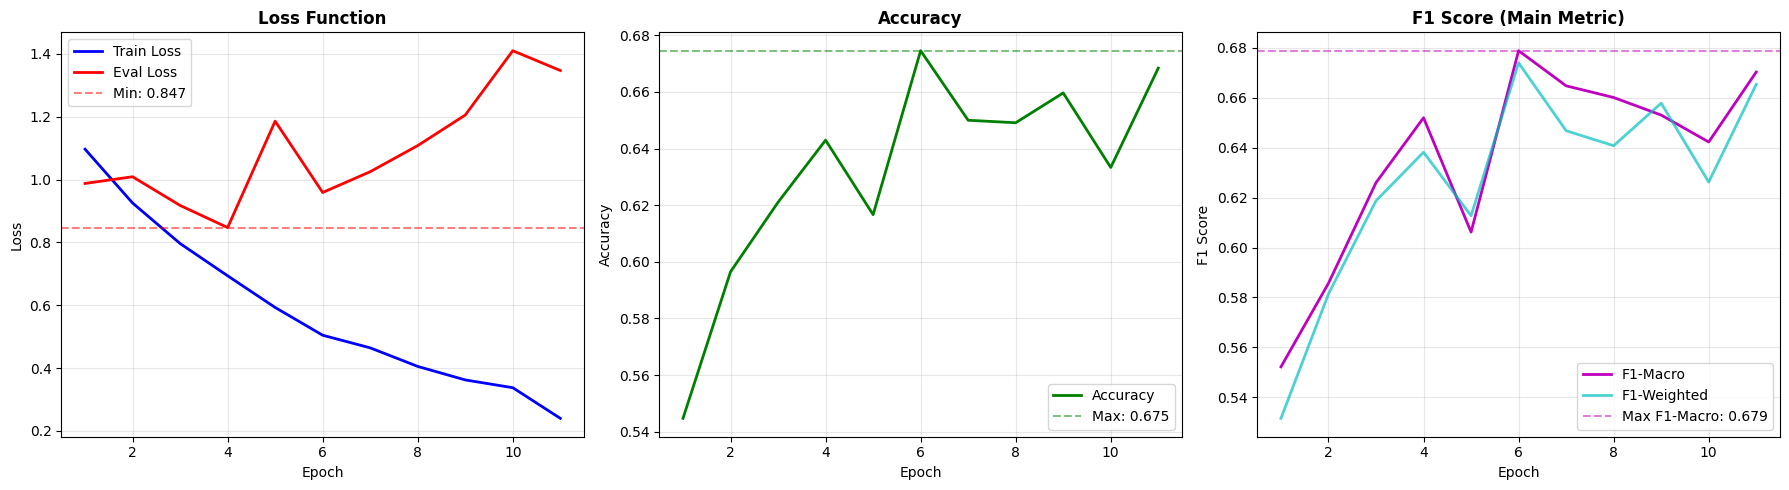


FINAL TRAINING STATISTICS

SELECTED MODEL (best macro-F1 on evaluation):
  - Epoch: 6
  - Eval loss: 0.9590
  - Accuracy: 0.6746
  - F1-macro: 0.6788
  - F1-weighted: 0.6739

LAST EPOCH:
  - Eval loss: 1.3473
  - Accuracy: 0.6684
  - F1-macro: 0.6703
  - F1-weighted: 0.6653

OVERFITTING GAP (selected epoch):
  - Train loss: 0.5046
  - Eval loss: 0.9590
  - Difference: 0.4544


In [15]:
print("\nGenerating training curves...")

history = trainer.state.log_history

# Filter the metrics
train_loss = [x['loss'] for x in history if 'loss' in x and 'eval_loss' not in x]
eval_loss = [x['eval_loss'] for x in history if 'eval_loss' in x]
eval_acc = [x['eval_accuracy'] for x in history if 'eval_accuracy' in x]
eval_f1_macro = [x['eval_f1_macro'] for x in history if 'eval_f1_macro' in x]
eval_f1_weighted = [x['eval_f1_weighted'] for x in history if 'eval_f1_weighted' in x]

epochs = range(1, len(eval_loss) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Loss
axes[0].plot(epochs, train_loss, 'b-', linewidth=2, label='Train Loss')
axes[0].plot(epochs, eval_loss, 'r-', linewidth=2, label='Eval Loss')
axes[0].set_title('Loss Function', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=min(eval_loss), color='r', linestyle='--', alpha=0.5, label=f'Min: {min(eval_loss):.3f}')
axes[0].legend()

# Plot 2: Accuracy
axes[1].plot(epochs, eval_acc, 'g-', linewidth=2, label='Accuracy')
axes[1].set_title('Accuracy', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].axhline(y=max(eval_acc), color='g', linestyle='--', alpha=0.5, label=f'Max: {max(eval_acc):.3f}')
axes[1].legend()

# Plot 3: Macro F1
axes[2].plot(epochs, eval_f1_macro, 'm-', linewidth=2, label='F1-Macro')
axes[2].plot(epochs, eval_f1_weighted, 'c-', linewidth=2, label='F1-Weighted', alpha=0.7)
axes[2].set_title('F1 Score (Main Metric)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('F1 Score')
axes[2].legend()
axes[2].grid(True, alpha=0.3)
axes[2].axhline(y=max(eval_f1_macro), color='m', linestyle='--', alpha=0.5, label=f'Max F1-Macro: {max(eval_f1_macro):.3f}')
axes[2].legend()

plt.tight_layout()
plt.savefig('./wav2vec2-emotions/training_curves.png', dpi=300, bbox_inches='tight')
print("Plot saved: training_curves.png")
plt.show()

# Final statistics
best_idx = int(np.argmax(eval_f1_macro))

print("\n" + "="*60)
print("FINAL TRAINING STATISTICS")
print("="*60)
print(f"\nSELECTED MODEL (best macro-F1 on evaluation):")
print(f"  - Epoch: {best_idx + 1}")
print(f"  - Eval loss: {eval_loss[best_idx]:.4f}")
print(f"  - Accuracy: {eval_acc[best_idx]:.4f}")
print(f"  - F1-macro: {eval_f1_macro[best_idx]:.4f}")
print(f"  - F1-weighted: {eval_f1_weighted[best_idx]:.4f}")

print(f"\nLAST EPOCH:")
print(f"  - Eval loss: {eval_loss[-1]:.4f}")
print(f"  - Accuracy: {eval_acc[-1]:.4f}")
print(f"  - F1-macro: {eval_f1_macro[-1]:.4f}")
print(f"  - F1-weighted: {eval_f1_weighted[-1]:.4f}")

print(f"\nOVERFITTING GAP (selected epoch):")
print(f"  - Train loss: {train_loss[best_idx]:.4f}")
print(f"  - Eval loss: {eval_loss[best_idx]:.4f}")
print(f"  - Difference: {abs(train_loss[best_idx] - eval_loss[best_idx]):.4f}")
if abs(train_loss[best_idx] - eval_loss[best_idx]) > 0.2:
    print("  WARNING: Possible overfitting (gap > 0.2)")
else:
    print("  Acceptable gap")



Running final evaluation on the evaluation set...



DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Neutral     0.6842    0.6393    0.6610       366
       Happy     0.6881    0.6609    0.6742       404
       Angry     0.6614    0.7812    0.7163       160
         Sad     0.6471    0.6810    0.6636       210

    accuracy                         0.6746      1140
   macro avg     0.6702    0.6906    0.6788      1140
weighted avg     0.6756    0.6746    0.6739      1140


Generating confusion matrix...
Confusion matrix saved: confusion_matrix.png


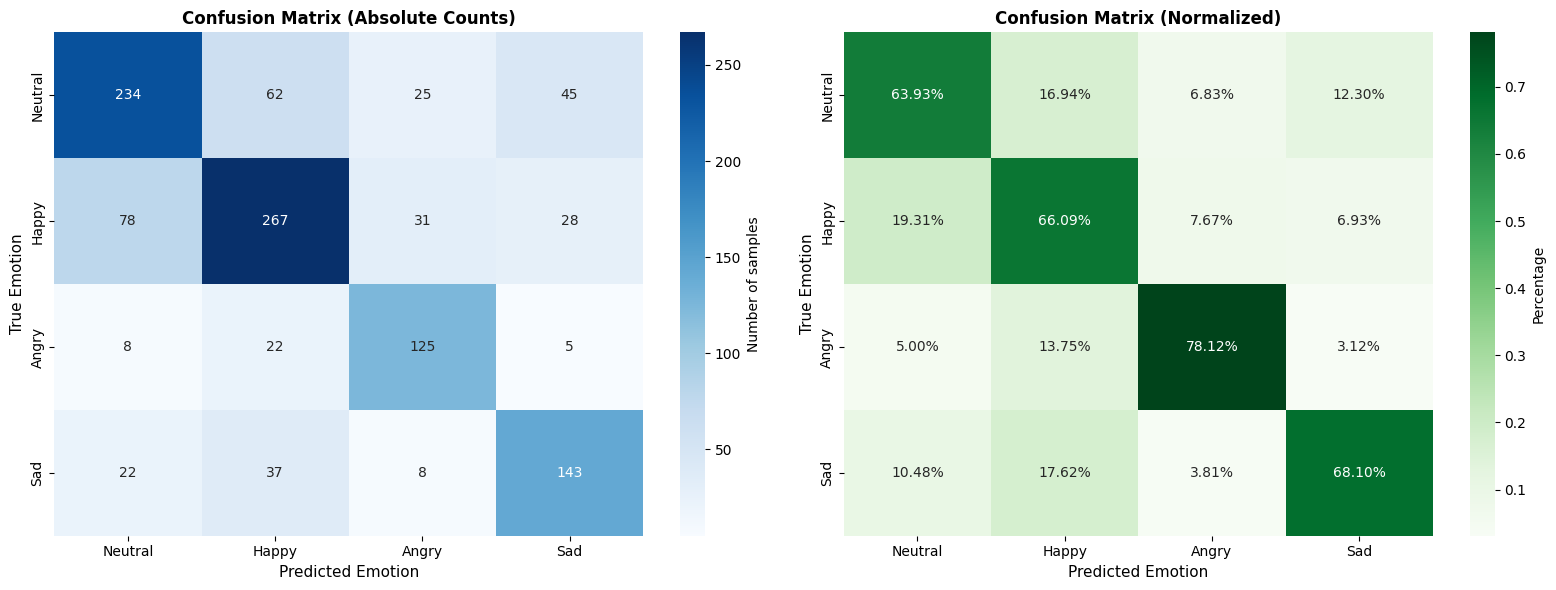


PER-CLASS ANALYSIS

NEUTRAL:
  - True samples: 366
  - Predicted samples: 342
  - Correctly classified: 234 (63.9%)
  - Precision: 0.6842
  - Recall: 0.6393
  - F1-Score: 0.6610

HAPPY:
  - True samples: 404
  - Predicted samples: 388
  - Correctly classified: 267 (66.1%)
  - Precision: 0.6881
  - Recall: 0.6609
  - F1-Score: 0.6742

ANGRY:
  - True samples: 160
  - Predicted samples: 189
  - Correctly classified: 125 (78.1%)
  - Precision: 0.6614
  - Recall: 0.7812
  - F1-Score: 0.7163

SAD:
  - True samples: 210
  - Predicted samples: 221
  - Correctly classified: 143 (68.1%)
  - Precision: 0.6471
  - Recall: 0.6810
  - F1-Score: 0.6636

GLOBAL METRICS
  - Accuracy: 0.6746 (67.46%)
  - F1-Macro: 0.6788
  - F1-Weighted: 0.6739
  - Precision-Macro: 0.6702
  - Recall-Macro: 0.6906

REFERENCE COMPARISON:
  - Majority-class accuracy: 0.3544 (35.44%)
  - Gain over majority class: 32.02 points

EVALUATION COMPLETED


In [16]:
# Run the final predictions
print("\nRunning final evaluation on the evaluation set...")

predictions = trainer.predict(encoded_eval)

# Get the true and predicted labels
y_true = predictions.label_ids
y_pred = np.argmax(predictions.predictions, axis=1)

# 1. DETAILED CLASSIFICATION REPORT
print("\n" + "="*60)
print("DETAILED CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# 2. CONFUSION MATRIX
print("\nGenerating confusion matrix...")

cm = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Absolute matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[0], cbar_kws={'label': 'Number of samples'})
axes[0].set_title('Confusion Matrix (Absolute Counts)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('True Emotion', fontsize=11)
axes[0].set_xlabel('Predicted Emotion', fontsize=11)

# Normalized matrix
sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[1], cbar_kws={'label': 'Percentage'})
axes[1].set_title('Confusion Matrix (Normalized)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('True Emotion', fontsize=11)
axes[1].set_xlabel('Predicted Emotion', fontsize=11)

plt.tight_layout()
plt.savefig('./wav2vec2-emotions/confusion_matrix.png', dpi=300, bbox_inches='tight')
print("Confusion matrix saved: confusion_matrix.png")
plt.show()

# 3. PER-CLASS ANALYSIS
print("\n" + "="*60)
print("PER-CLASS ANALYSIS")
print("="*60)

from sklearn.metrics import precision_score, recall_score, f1_score

precisions = precision_score(y_true, y_pred, average=None)
recalls = recall_score(y_true, y_pred, average=None)
f1s = f1_score(y_true, y_pred, average=None)

for i, class_name in enumerate(class_names):
    precision = precisions[i]
    recall = recalls[i]
    f1 = f1s[i]

    total_true = np.sum(np.array(y_true) == i)
    total_pred = np.sum(np.array(y_pred) == i)
    correct = np.sum((np.array(y_true) == i) & (np.array(y_pred) == i))

    print(f"\n{class_name.upper()}:")
    print(f"  - True samples: {total_true}")
    print(f"  - Predicted samples: {total_pred}")
    print(f"  - Correctly classified: {correct} ({correct/total_true*100:.1f}%)")
    print(f"  - Precision: {precision:.4f}")
    print(f"  - Recall: {recall:.4f}")
    print(f"  - F1-Score: {f1:.4f}")


# 4. GLOBAL METRICS
print("\n" + "="*60)
print("GLOBAL METRICS")
print("="*60)

accuracy = np.mean(np.array(y_true) == np.array(y_pred))
f1_macro = f1_score(y_true, y_pred, average='macro')
f1_weighted = f1_score(y_true, y_pred, average='weighted')
precision_macro = precision_score(y_true, y_pred, average='macro')
recall_macro = recall_score(y_true, y_pred, average='macro')

print(f"  - Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"  - F1-Macro: {f1_macro:.4f}")
print(f"  - F1-Weighted: {f1_weighted:.4f}")
print(f"  - Precision-Macro: {precision_macro:.4f}")
print(f"  - Recall-Macro: {recall_macro:.4f}")

print("\nREFERENCE COMPARISON:")
majority_acc = np.bincount(y_true).max() / len(y_true)
print(f"  - Majority-class accuracy: {majority_acc:.4f} ({majority_acc*100:.2f}%)")
print(f"  - Gain over majority class: {(accuracy - majority_acc)*100:.2f} points")

print("\n" + "="*60)
print("EVALUATION COMPLETED")
print("="*60)